In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import gamma, pi, ceil

SEED = 2026
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")

In [12]:
f_star = lambda x: np.sin(2*np.pi*x) + 0.5*x
n, sigma, B = 250, 0.25, 1000
x_points = [0.50, 0.05]
ks = [1, 2, 5, 10, 20, 40, 80]

X = rng.uniform(0, 1, n)          # fixed training features
fX = f_star(X)

rows = []
for x0 in x_points:
    order = np.argsort(np.abs(X - x0))          # neighbours sorted by distance
    eps = rng.normal(0, sigma, size=(B, n))     # B fresh noise vectors
    Y = fX + eps                                # B training response vectors
    for k in ks:
        idx = order[:k]
        preds = Y[:, idx].mean(axis=1)          # k-NN prediction in each repetition
        theo_mean = fX[idx].mean()
        rows.append(dict(x=x0, k=k,
                         emp_mean=preds.mean(), theo_mean=theo_mean,
                         emp_var=preds.var(ddof=1), theo_var=sigma**2/k,
                         bias2=(f_star(x0) - theo_mean)**2,
                         farthest_nb=np.abs(X[idx] - x0).max()))
df = pd.DataFrame(rows)
df["emp_MSE"] = df["bias2"] + df["emp_var"]
df["theo_MSE"] = df["bias2"] + df["theo_var"]

In [13]:
cmp = df[["x", "k", "emp_mean", "theo_mean", "emp_var", "theo_var"]].copy()
cmp["mean_diff"] = cmp["emp_mean"] - cmp["theo_mean"]
cmp["var_ratio"] = cmp["emp_var"] / cmp["theo_var"]
cmp

,x,k,emp_mean,theo_mean,emp_var,theo_var,mean_diff,var_ratio
0,0.5,1,0.248207,0.25026,0.0655735,0.0625,-0.00205345,1.04918
1,0.5,2,0.256764,0.253979,0.0317632,0.03125,0.00278468,1.01642
2,0.5,5,0.276015,0.271716,0.012364,0.0125,0.00429909,0.989123
3,0.5,10,0.295102,0.293061,0.00596458,0.00625,0.00204093,0.954333
4,0.5,20,0.287331,0.286678,0.0030498,0.003125,0.000652714,0.975936
5,0.5,40,0.224423,0.223633,0.00151417,0.0015625,0.000789345,0.96907
6,0.5,80,0.191735,0.191119,0.000806836,0.00078125,0.000615339,1.03275
7,0.05,1,0.295455,0.288996,0.0608287,0.0625,0.00645894,0.973259
8,0.05,2,0.344546,0.339544,0.0295676,0.03125,0.00500176,0.946165
9,0.05,5,0.309988,0.310332,0.012561,0.0125,-0.00034387,1.00488


the mean differences are tiny (within Monte Carlo error σ/√(kB)), and the variance ratios are all close to 1 (about 0.95 to 1.05). The formulas are confirmed.

Question 2: table and plot of Bias², σ²/k and their sum

In [14]:
df[["x", "k", "bias2", "theo_var", "theo_MSE", "emp_MSE", "farthest_nb"]]

,x,k,bias2,theo_var,theo_MSE,emp_MSE,farthest_nb
0,0.5,1,6.76592e-08,0.0625,0.0625001,0.0655735,4.49776e-05
1,0.5,2,1.58334e-05,0.03125,0.0312658,0.0317791,0.00133114
2,0.5,5,0.000471577,0.0125,0.0129716,0.0128356,0.00688968
3,0.5,10,0.00185427,0.00625,0.00810427,0.00781886,0.0150848
4,0.5,20,0.00134528,0.003125,0.00447028,0.00439508,0.0381164
5,0.5,40,0.000695204,0.0015625,0.0022577,0.00220938,0.0694729
6,0.5,80,0.00346695,0.00078125,0.0042482,0.00427379,0.141918
7,0.05,1,0.00202685,0.0625,0.0645268,0.0628555,0.00690931
8,0.05,2,3.05492e-05,0.03125,0.0312805,0.0295982,0.00873522
9,0.05,5,0.000560993,0.0125,0.013061,0.013122,0.0195352


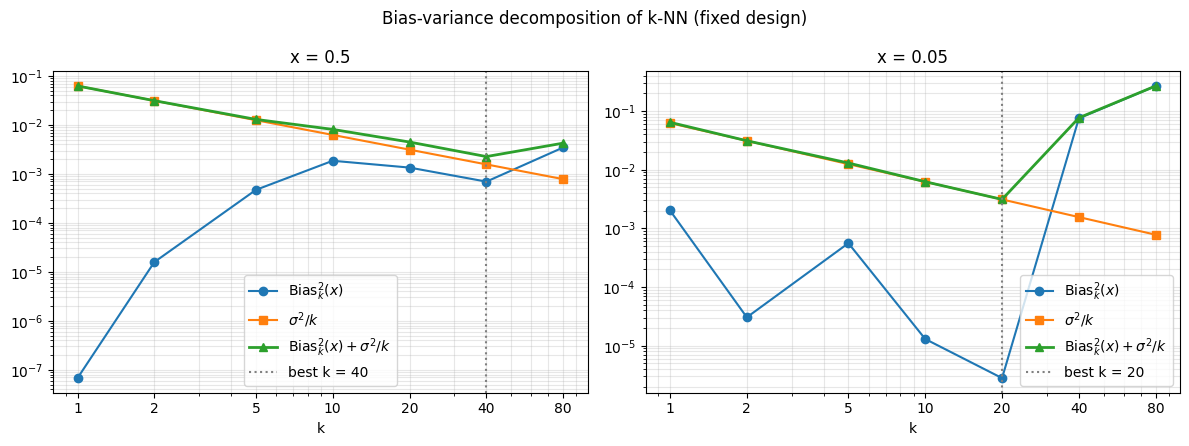

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, x0 in zip(axes, x_points):
    d = df[df.x == x0]
    ax.plot(d.k, d.bias2, "o-", label=r"$\mathrm{Bias}_k^2(x)$")
    ax.plot(d.k, d.theo_var, "s-", label=r"$\sigma^2/k$")
    ax.plot(d.k, d.theo_MSE, "^-", lw=2, label=r"$\mathrm{Bias}_k^2(x)+\sigma^2/k$")
    kb = d.loc[d.theo_MSE.idxmin(), "k"]
    ax.axvline(kb, color="gray", ls=":", label=f"best k = {kb}")
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xticks(ks); ax.set_xticklabels(ks)
    ax.set_xlabel("k"); ax.set_title(f"x = {x0}")
    ax.grid(alpha=0.3, which="both"); ax.legend()
plt.suptitle("Bias-variance decomposition of k-NN (fixed design)")
plt.tight_layout(); plt.show()

Question 3: find the best k:? Result: k = 40 at x = 0.50, k = 20 at x = 0.05

In [16]:
for x0 in x_points:
    d = df[df.x == x0]
    print(f"x = {x0}: best k = {d.loc[d.theo_MSE.idxmin(), 'k']} "
          f"(min Bias^2 + sigma^2/k = {d.theo_MSE.min():.5f})")

x = 0.5: best k = 40 (min Bias^2 + sigma^2/k = 0.00226)
x = 0.05: best k = 20 (min Bias^2 + sigma^2/k = 0.00313)


1) The variance σ²/k is identical at both points, so the difference comes from the bias.
2) At x = 0.50 the neighbours lie on both sides of x, so the linear part of f* cancels in the average. Also, x = 0.5 is an inflection point of sin(2πx), so f* is almost straight there. The bias stays small until k is large.
3) At x = 0.05 there is only 0.05 of space on the left. Once k goes past about 20, all new neighbours come from the right, so the neighbourhood is one sided. The slope there is steep (about 6.5) and f* rises toward its peak at 0.25, so the average is pulled upward. Bias² jumps from about 0.000003 at k = 20 to 0.076 at k = 40.


In Conclusion, near the boundary k-NN must stay more local (smaller k). This is the boundary bias of local averaging.

Part II. How much data does high dimension cost?

Step 1. Question 4: derive the formula.
Start from n·V_d·r₀ᵈ ≈ k and solve for n:

$$n_d = \frac{k}{V_d\, r_0^d}, \qquad V_d = \frac{\pi^{d/2}}{\Gamma(d/2+1)}$$

Note to include: r₀ = 0.3 < 0.5, so the ball around the centre stays fully inside the cube, and its probability is exactly V_d·r₀ᵈ.

In [17]:
k, r0 = 10, 0.30
dims = [1, 2, 3, 5, 8, 10, 15]
V = lambda d: pi**(d/2) / gamma(d/2 + 1)

tab = pd.DataFrame({"d": dims})
tab["V_d"] = [V(d) for d in dims]
tab["r0^d"] = [r0**d for d in dims]
tab["n_d = k/(V_d r0^d)"] = [k/(V(d)*r0**d) for d in dims]
tab["ceil(n_d)"] = [ceil(k/(V(d)*r0**d)) for d in dims]
tab

,d,V_d,r0^d,n_d = k/(V_d r0^d),ceil(n_d)
0,1,2,0.3,16.6667,17
1,2,3.14159,0.09,35.3678,36
2,3,4.18879,0.027,88.4194,89
3,5,5.26379,0.00243,781.799,782
4,8,4.05871,6.561e-05,37552.7,37553
5,10,2.55016,5.9049e-06,664078,664079
6,15,0.381443,1.43489e-08,1.82705e+09,1827053271


Check one value by hand. For d = 2: V₂ = π, r₀² = 0.09, so n = 10/(π·0.09) ≈ 35.37, rounded up to 36.

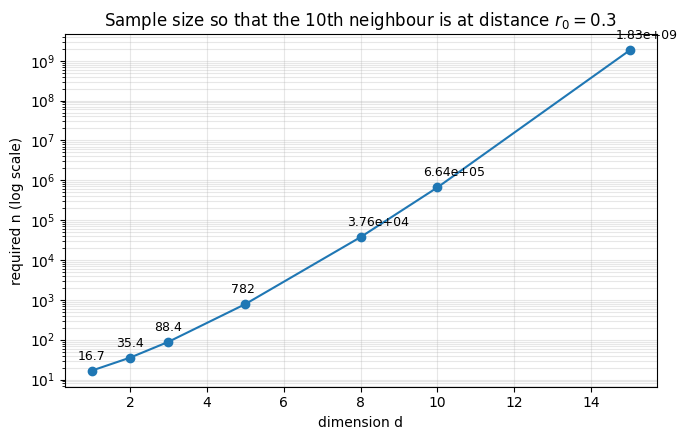

In [18]:
plt.figure(figsize=(7, 4.5))
plt.semilogy(tab["d"], tab["n_d = k/(V_d r0^d)"], "o-")
for d, nd in zip(tab["d"], tab["n_d = k/(V_d r0^d)"]):
    plt.annotate(f"{nd:.3g}", (d, nd), textcoords="offset points", xytext=(-10, 8), fontsize=9)
plt.xlabel("dimension d"); plt.ylabel("required n (log scale)")
plt.title(r"Sample size so that the 10th neighbour is at distance $r_0=0.3$")
plt.grid(alpha=0.3, which="both"); plt.tight_layout(); plt.show()

Question 5: verify by simulation.
For d = 2, 5, 8: take n = ⌈n_d⌉, generate n uniform points in the cube, compute each point’s distance to the centre (0.5, ..., 0.5), and take the 10th smallest. np.partition finds it without sorting the whole array. Repeat 30 times and average.

In [19]:
rng2 = np.random.default_rng(SEED)
R = 30
sim = []
for d in [2, 5, 8]:
    nd = ceil(k/(V(d)*r0**d))
    dists = []
    for _ in range(R):
        Xs = rng2.uniform(0, 1, size=(nd, d))
        r = np.linalg.norm(Xs - 0.5, axis=1)
        dists.append(np.partition(r, k-1)[k-1])   # k-th smallest distance
    dists = np.array(dists)
    sim.append(dict(d=d, n=nd, mean_R10=dists.mean(), std_R10=dists.std(ddof=1),
                    se=dists.std(ddof=1)/np.sqrt(R), rel_error=(dists.mean()-r0)/r0))
pd.DataFrame(sim)

,d,n,mean_R10,std_R10,se,rel_error
0,2,36,0.299014,0.0425803,0.00777407,-0.00328542
1,5,782,0.297209,0.0229292,0.00418628,-0.00930186
2,8,37553,0.301641,0.0118695,0.00216707,0.00547064


Question 6: the factor for halving the radius.

From R ≈ (k/(n·V_d))^(1/d), the radius is proportional to n^(−1/d).
Set the new radius to half the old one: (n/n′)^(1/d) = 1/2.
Raise both sides to the power d: n/n′ = 1/2ᵈ, so n′ = 2ᵈ · n.

In [20]:
pd.DataFrame({"d": dims, "factor 2^d": [2**d for d in dims]}).T

,0,1,2,3,4,5,6
d,1,2,3,5,8,10,15
factor 2^d,2,4,8,32,256,1024,32768


In 1D, halving the radius only doubles the data. In 10D it needs 1024 times more data, and in 15D about 32,768 times more. A ball of fixed radius covers a fraction V_d·rᵈ of the cube that shrinks exponentially with d. So for realistic sample sizes, the “nearest” neighbours in high dimension are actually far away, k-NN averages over a large region, and the bias grows. Local methods therefore need exponentially more data as dimension increases: from 17 points at d = 1 to about 1.8 billion at d = 15, for the same k and r₀.